# Préparation des données — Agritech Answers

**Étape 1 — Consolidation.** Produit le **dataset unique** qui servira de source de vérité aux étapes suivantes : nettoyage des six fichiers, construction du référentiel FAO, création des variables.

S'appuie sur `exploratory_data_analysis.ipynb` sans en refaire les constats.

| Constat de l'exploration | Conséquence ici |
|---|---|
| Tout se passe comme si le jeu A suivait une relation additive simple, de plafond R² ≈ 0,913 | Aucune variable créée ne devrait améliorer la prédiction — **vérifié en §8** |
| `Crop` sans effet mesurable (η² = 0,000006) | La recommandation exige un apport externe : c'est l'objet du §6 |
| `yield_df.csv` amputé de 76,8 % et gonflé par duplication | Référentiel rebâti depuis `yield.csv` ; `yield_df` sert de contrôle (§5) |
| `rainfall.csv` = normale climatique constante par pays | Écartée comme variable explicative |
| `temp.csv` : 7 534 couples à valeurs divergentes | Agrégation médiane **avant** jointure |

| § | Étape |
|---|---|
| 1-2 | Configuration, contrôle qualité des six fichiers |
| 3 | Nettoyage fichier par fichier |
| 4-5 | Panel FAO par jointures gauches, puis validation |
| 6 | Référentiel par culture |
| 7 | Enrichissement des parcelles et variables de parcelle |
| 8 | Validation hors échantillon |
| 9-10 | Dictionnaire, export, synthèse |

## 1. Configuration

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(PROJECT_ROOT))

from config import (
    BLUE,
    CONSOLIDATED_PARQUET_PATH,
    CONSOLIDATED_PATH,
    CROP_MAPPING,
    CROP_REFERENCE_PATH,
    CROP_YIELD_PATH,
    CROPS_WITHOUT_REFERENCE,
    DATA_DICTIONARY_PATH,
    FAO_PANEL_PATH,
    GREEN,
    INTERIM_DIR,
    HG_PER_HA_TO_T_PER_HA,
    ORANGE,
    PESTICIDES_PATH,
    PROCESSED_DIR,
    RAINFALL_PATH,
    RANDOM_STATE,
    TARGET,
    TEMP_PATH,
    YIELD_DF_PATH,
    YIELD_RAW_PATH,
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda v: format(v, ',.3f'))
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

KEY_FAO = ['Area', 'Item', 'Year']
SEUIL_FAIBLE_PLUIE_MM = 400   # tiers inferieur de la plage observee (100-1000 mm),
                              # ordre de grandeur du seuil semi-aride usuel

In [2]:
def controle(df, nom, cle=None):
    # Fiche de controle commune a tous les fichiers : volume, manquants, doublons
    ligne = {
        'fichier': nom,
        'lignes': len(df),
        'colonnes': df.shape[1],
        'cellules_nan': int(df.isna().sum().sum()),
        'colonnes_avec_nan': int((df.isna().sum() > 0).sum()),
        'doublons_stricts': int(df.duplicated().sum()),
    }
    ligne['doublons_sur_cle'] = int(df.duplicated(subset=cle).sum()) if cle else 0
    return ligne


def colonnes_constantes(df):
    # Colonnes a valeur unique : aucune information, donc supprimables
    return [col for col in df.columns if df[col].nunique(dropna=False) <= 1]

## 2. Chargement et contrôle qualité des six fichiers

Mêmes critères pour chaque fichier, avant tout traitement.

In [3]:
parcelles = pd.read_csv(CROP_YIELD_PATH)
fao_brut = pd.read_csv(YIELD_RAW_PATH)
pesticides_brut = pd.read_csv(PESTICIDES_PATH)
pluie_brut = pd.read_csv(RAINFALL_PATH)
temperatures_brut = pd.read_csv(TEMP_PATH)
fusion_fournie = pd.read_csv(YIELD_DF_PATH, index_col=0)

etat_initial = pd.DataFrame([
    controle(parcelles, 'crop_yield.csv'),
    controle(fao_brut, 'yield.csv', KEY_FAO),
    controle(pesticides_brut, 'pesticides.csv', ['Area', 'Year']),
    controle(pluie_brut, 'rainfall.csv'),
    controle(temperatures_brut, 'temp.csv', ['country', 'year']),
    controle(fusion_fournie, 'yield_df.csv', KEY_FAO),
]).set_index('fichier')
etat_initial

,lignes,colonnes,cellules_nan,colonnes_avec_nan,doublons_stricts,doublons_sur_cle
fichier,,,,,,
crop_yield.csv,1000000,10,0,0,0,0
yield.csv,56717,12,0,0,0,0
pesticides.csv,4349,7,0,0,0,0
rainfall.csv,6727,3,774,1,0,0
temp.csv,71311,3,2547,1,6958,42797
yield_df.csv,28242,7,0,0,2310,15112


> **Lecture.** `rainfall.csv` et `temp.csv` portent des valeurs manquantes déclarées ; `rainfall.csv` en masque six de plus sous forme de texte (`'..'`), invisibles à `isna()`. Les seuls doublons sur clé métier sont dans `temp.csv`, et par héritage dans `yield_df.csv`.

## 3. Nettoyage fichier par fichier

### 3.1 Jeu A — rendements physiquement impossibles

In [4]:
avant = len(parcelles)
negatifs = parcelles[TARGET] < 0

parcelles = parcelles[~negatifs].reset_index(drop=True)

print('Rendements negatifs supprimes :', f'{int(negatifs.sum()):,}',
      f'({100 * negatifs.mean():.4f} %)')
print('Lignes conservees :', f'{len(parcelles):,}', 'sur', f'{avant:,}')
print('Valeurs manquantes :', int(parcelles.isna().sum().sum()),
      '| doublons stricts :', int(parcelles.duplicated().sum()))

Rendements negatifs supprimes : 231 (0.0231 %)
Lignes conservees : 999,769 sur 1,000,000


Valeurs manquantes : 0 | doublons stricts : 0


> Un rendement négatif est physiquement impossible : suppression, pour un volume négligeable. Les rendements faibles mais positifs sont **conservés** — parcelles sèches sans intrants, parfaitement plausibles. L'origine probable de ces valeurs est examinée en §8.4.

### 3.2 `temp.csv` — agréger avant de joindre

In [5]:
temperatures = (temperatures_brut
                .rename(columns={'year': 'Year', 'country': 'Area'})
                .groupby(['Area', 'Year'], as_index=False)['avg_temp']
                .median())

print('Avant agregation :', f'{len(temperatures_brut):,}', 'lignes |',
      'doublons sur (pays, annee) :',
      f'{int(temperatures_brut.duplicated(subset=["country", "year"]).sum()):,}',
      '| avg_temp manquants :', int(temperatures_brut['avg_temp'].isna().sum()))
print('Apres agregation :', f'{len(temperatures):,}', 'lignes |',
      'doublons :', int(temperatures.duplicated(subset=['Area', 'Year']).sum()),
      '| couples sans aucune mesure :', int(temperatures['avg_temp'].isna().sum()))

temperatures = temperatures.dropna(subset=['avg_temp']).reset_index(drop=True)
print('Conservees :', f'{len(temperatures):,}')

Avant agregation : 71,311 lignes | doublons sur (pays, annee) : 42,797 | avg_temp manquants : 2547
Apres agregation : 28,514 lignes | doublons : 0 | couples sans aucune mesure : 1035
Conservees : 27,479


> Correction décisive : agréger **après** la jointure aurait laissé la duplication fausser toute pondération. Médiane plutôt que moyenne, les écarts intra-couple atteignant 27,9 °C.

### 3.3 `rainfall.csv` — valeurs manquantes masquées en texte

In [6]:
pluie = pluie_brut.copy()
pluie.columns = [col.strip() for col in pluie.columns]      # ' Area' porte un espace initial

COL_PLUIE = 'average_rain_fall_mm_per_year'
pluie['rain_mm'] = pd.to_numeric(pluie[COL_PLUIE], errors='coerce')

masquees = pluie['rain_mm'].isna()
print('Valeurs non convertibles revelees :', f'{int(masquees.sum()):,}',
      f'({100 * masquees.mean():.1f} %)')
print('Exemples de valeurs fautives :', pluie.loc[masquees, COL_PLUIE].unique()[:3])

pluie = pluie.loc[~masquees, ['Area', 'Year', 'rain_mm']].reset_index(drop=True)
print('Lignes conservees :', f'{len(pluie):,}')

Valeurs non convertibles revelees : 780 (11.6 %)
Exemples de valeurs fautives : <ArrowStringArray>
[nan, '..']
Length: 2, dtype: str
Lignes conservees : 5,947


> Deux natures de manquants : **774 valeurs vides** que `isna()` détecte, et **6 encodées `'..'`** que seule la conversion numérique révèle. Supprimées plutôt qu'imputées : cette variable ne sert qu'à décrire les zones de culture dans la table de référence.

### 3.4 `yield.csv` et `pesticides.csv` — colonnes sans information

In [7]:
print('yield.csv      — colonnes constantes :', colonnes_constantes(fao_brut))
print('pesticides.csv — colonnes constantes :', colonnes_constantes(pesticides_brut))
print('yield.csv      — Year identique a Year Code :',
      bool((fao_brut['Year'] == fao_brut['Year Code']).all()))

# On ne garde que les colonnes porteuses d'information
rendements = fao_brut[['Area', 'Item', 'Year', 'Value']].rename(columns={'Value': 'yield_hg_ha'})
rendements['yield_t_ha'] = rendements['yield_hg_ha'] / HG_PER_HA_TO_T_PER_HA

pesticides = (pesticides_brut[['Area', 'Year', 'Value']]
              .rename(columns={'Value': 'pesticides_t'}))

print()
print('rendements :', rendements.shape, '| pesticides :', pesticides.shape)
print('rendements <= 0 :', int((rendements['yield_t_ha'] <= 0).sum()), '-> supprimes')
rendements = rendements[rendements['yield_t_ha'] > 0].reset_index(drop=True)

yield.csv      — colonnes constantes : ['Domain Code', 'Domain', 'Element Code', 'Element', 'Unit']
pesticides.csv — colonnes constantes : ['Domain', 'Element', 'Item', 'Unit']
yield.csv      — Year identique a Year Code : True

rendements : (56717, 5) | pesticides : (4349, 3)
rendements <= 0 : 8 -> supprimes


## 4. Construction du panel FAO

Trois règles issues du diagnostic de `yield_df.csv` : **agréger avant de joindre**, **jointure gauche** plutôt qu'interne, et **ne pas sacrifier d'observations** pour obtenir une variable peu informative.

In [8]:
# Validation de cardinalite AVANT jointure : chaque table annexe doit porter
# au plus une ligne par couple (pays, annee), sans quoi la jointure dupliquerait
for nom, table in [('temperatures', temperatures), ('pluie', pluie), ('pesticides', pesticides)]:
    doublons = int(table.duplicated(subset=['Area', 'Year']).sum())
    assert doublons == 0, f'{nom} : {doublons} doublons sur (Area, Year)'
    print(f'{nom:<14} {len(table):>7,} lignes | une seule ligne par (pays, annee) : OK')

panel = (rendements
         .merge(temperatures, on=['Area', 'Year'], how='left', validate='many_to_one')
         .merge(pluie, on=['Area', 'Year'], how='left', validate='many_to_one')
         .merge(pesticides, on=['Area', 'Year'], how='left', validate='many_to_one'))

assert len(panel) == len(rendements), 'La jointure a modifie le nombre de lignes'

couverture = pd.DataFrame({
    'renseignée_%': (100 * panel[['avg_temp', 'rain_mm', 'pesticides_t']].notna().mean()).round(1),
    'valeurs_manquantes': panel[['avg_temp', 'rain_mm', 'pesticides_t']].isna().sum(),
})
print()
print('Panel FAO :', f'{len(panel):,}', 'lignes | aucune duplication introduite')
couverture

temperatures    27,479 lignes | une seule ligne par (pays, annee) : OK
pluie            5,947 lignes | une seule ligne par (pays, annee) : OK
pesticides       4,349 lignes | une seule ligne par (pays, annee) : OK

Panel FAO : 56,709 lignes | aucune duplication introduite


,renseignée_%,valeurs_manquantes
avg_temp,56.800,24499
rain_mm,44.800,31324
pesticides_t,42.600,32564


> Toutes les observations de rendement sont conservées, aucun doublon introduit — là où la recette d'origine en perdait 76,8 %. Les covariables sont partiellement renseignées : c'est un prix explicite, non subi.

## 5. Validation du panel contre `yield_df.csv`

In [9]:
reference_fournie = fusion_fournie.drop_duplicates(subset=KEY_FAO)[KEY_FAO + ['hg/ha_yield']]
controle_croise = panel.merge(reference_fournie, on=KEY_FAO, how='inner')
ecart = (controle_croise['yield_hg_ha'] - controle_croise['hg/ha_yield']).abs()

print('Observations communes          :', f'{len(controle_croise):,}')
print('Rendements strictement egaux   :', f'{int((ecart == 0).sum()):,}',
      f'({100 * (ecart == 0).mean():.2f} %)')
print('Ecart maximal observe          :', ecart.max())
print()
print('Gain de notre panel :', f'{len(panel) / len(reference_fournie):.1f}x observations,',
      panel['Area'].nunique(), 'pays contre', reference_fournie['Area'].nunique())

Observations communes          : 13,130
Rendements strictement egaux   : 13,130 (100.00 %)
Ecart maximal observe          : 0

Gain de notre panel : 4.3x observations, 212 pays contre 101


> Les rendements coïncident **exactement** sur les 13 130 observations communes : même socle, débarrassé des pertes et des duplications.

## 6. Référentiel par culture

Le jeu A ne contient aucune information différenciant les cultures. Ce référentiel en est la seule source possible.

### 6.1 Un indice mondial serait biaisé

In [10]:
cultures_fao = list(CROP_MAPPING.values())
panel_cultures = panel[panel['Item'].isin(cultures_fao)]

# Classement mondial (mediane brute) contre classement intra-pays (rang moyen)
mediane_mondiale = panel_cultures.groupby('Item')['yield_t_ha'].median()

par_pays = panel_cultures.pivot_table(index='Area', columns='Item',
                                      values='yield_t_ha', aggfunc='median').dropna()
rang_moyen = par_pays.rank(axis=1, ascending=False).mean()

diagnostic = pd.DataFrame({
    'mediane_mondiale_t_ha': mediane_mondiale.round(2),
    'rang_mondial': mediane_mondiale.rank(ascending=False).astype(int),
    'rang_moyen_intra_pays': rang_moyen.round(2),
    'rang_intra_pays': rang_moyen.rank().astype(int),
})
print('Pays cultivant les 4 cultures :', len(par_pays))
diagnostic.sort_values('rang_intra_pays')

Pays cultivant les 4 cultures : 67


,mediane_mondiale_t_ha,rang_mondial,rang_moyen_intra_pays,rang_intra_pays
Item,,,,
"Rice, paddy",2.630,1,1.470,1
Maize,1.740,3,2.160,2
Wheat,2.000,2,2.860,3
Soybeans,1.300,4,3.510,4


> **Paradoxe de Simpson.** Classement mondial et classement intra-pays divergent : en médiane mondiale le blé devance le maïs, au sein des pays c'est l'inverse. La médiane mondiale mesure donc en partie *quels pays cultivent quoi*.
>
> L'indice sera normalisé **par pays**, ce qui **réduit** l'effet pays sans l'annuler : les périodes couvertes et les systèmes agricoles restent hétérogènes.

### 6.2 Construction des variables de référence

In [11]:
# Indice intra-pays : rendement de la culture rapporte a la mediane du pays,
# puis mediane de ces ratios. Cela REDUIT les ecarts de niveau entre pays,
# sans neutraliser les effets d'annee, de composition ni de couverture.
mediane_par_pays = panel_cultures.groupby('Area')['yield_t_ha'].transform('median')
ratios = panel_cultures.assign(ratio=panel_cultures['yield_t_ha'] / mediane_par_pays)

reference = pd.DataFrame({
    # 1. Productivite relative, corrigee de l'effet pays
    'crop_productivity_index': ratios.groupby('Item')['ratio'].median(),
    # 2. Niveau absolu de reference
    'crop_yield_ref_t_ha': panel_cultures.groupby('Item')['yield_t_ha'].median(),
    # 3. Dispersion des rendements ENTRE PAYS : une variabilite geographique,
    #    qui ne mesure pas le risque encouru par une parcelle donnee
    'crop_yield_geo_cv': (par_pays.std() / par_pays.mean()),
    # 5. Etendue de culture = robustesse de la reference
    'crop_countries': panel_cultures.groupby('Item')['Area'].nunique(),
})

# 4. Tendance historique, en t/ha par decennie
tendances = {}
for culture, groupe in panel_cultures.groupby('Item'):
    serie = groupe.groupby('Year')['yield_t_ha'].median()
    tendances[culture] = np.polyfit(serie.index, serie.to_numpy(), 1)[0] * 10
reference['crop_yield_trend_decade'] = pd.Series(tendances)

# Plages climatiques observees : ou chaque culture est reellement cultivee
climat = panel_cultures.dropna(subset=['avg_temp']).groupby('Item')['avg_temp']
reference['crop_temp_p10'] = climat.quantile(0.10)
reference['crop_temp_p90'] = climat.quantile(0.90)
pluviometrie = panel_cultures.dropna(subset=['rain_mm']).groupby('Item')['rain_mm']
reference['crop_rain_p10'] = pluviometrie.quantile(0.10)
reference['crop_rain_p90'] = pluviometrie.quantile(0.90)

# Contexte d'intensification, conserve pour controle (voir 6.3)
reference['crop_pesticides_context_t'] = panel_cultures.groupby('Item')['pesticides_t'].median()

reference.round(3)

,crop_productivity_index,crop_yield_ref_t_ha,crop_yield_geo_cv,crop_countries,crop_yield_trend_decade,crop_temp_p10,crop_temp_p90,crop_rain_p10,crop_rain_p90,crop_pesticides_context_t
Item,,,,,,,,,,
Maize,1.010,1.739,0.670,180,0.430,9.492,27.200,206.000,"2,331.000","1,597.000"
"Rice, paddy",1.429,2.627,0.456,128,0.360,11.876,27.280,322.000,"2,592.000","1,766.750"
Soybeans,0.639,1.299,0.455,108,0.152,9.483,26.860,495.000,"2,280.000","3,650.080"
Wheat,0.912,2.000,0.543,133,0.326,7.540,26.000,151.000,"1,732.000","2,536.150"


> **Un optimum thermique par culture a été envisagé puis abandonné** : les ajustements quadratiques plaçaient les sommets à **−8,4 °C pour le blé** et −2,1 °C pour le soja, hors plage observée, avec des R² de 0,12 à 0,22 — des artefacts de confusion entre climat et niveau de développement, non des optima.
>
> Les déciles climatiques des pays producteurs décrivent en revanche un fait observé, sans modèle interposé.

### 6.3 La variable pesticides apporte-t-elle quelque chose ?

In [12]:
correlation = panel_cultures[['yield_t_ha', 'pesticides_t', 'rain_mm', 'avg_temp']].corr()['yield_t_ha']
print('Correlation des covariables FAO avec le rendement :')
print(correlation.drop('yield_t_ha').round(3).to_string())
print()
print('Ecart entre cultures sur le contexte pesticides :')
print(reference['crop_pesticides_context_t'].round(0).to_string())

Correlation des covariables FAO avec le rendement :
pesticides_t    0.090
rain_mm        -0.157
avg_temp       -0.327

Ecart entre cultures sur le contexte pesticides :
Item
Maize         1,597.000
Rice, paddy   1,767.000
Soybeans      3,650.000
Wheat         2,536.000


> **`pesticides_t` écartée.** Corrélation au rendement négligeable, et au niveau culture elle mesure la taille agricole des pays producteurs, pas une pratique. Le fichier est exploité et documenté ; constater qu'il n'informe pas est un résultat.

## 7. Enrichissement par référentiel de culture

**Ce n'est pas une jointure entre les deux jeux.** Le jeu A n'ayant ni pays ni année, aucun appariement observation par observation n'est possible : on **diffuse une table de 4 lignes** sur un million de parcelles, via la seule clé disponible — la culture.

Parler de « jointure » laisserait croire à une correspondance géographique et temporelle qui n'existe pas.

In [13]:
# Vocabulaire FAO -> vocabulaire du jeu A
COLONNES_REFERENCE = ['crop_productivity_index', 'crop_yield_ref_t_ha', 'crop_yield_geo_cv',
                      'crop_yield_trend_decade', 'crop_countries']

reference_diffusee = reference[COLONNES_REFERENCE].copy()
reference_diffusee.index = reference_diffusee.index.map(
    {valeur: cle for cle, valeur in CROP_MAPPING.items()})
reference_diffusee = reference_diffusee.loc[reference_diffusee.index.notna()]

avant = len(parcelles)
dataset = parcelles.merge(reference_diffusee, left_on='Crop', right_index=True, how='left')

# Rapport de cardinalite : une ligne de parcelle doit rester une ligne de parcelle
cultures_jeu_a = set(parcelles['Crop'].unique())
cultures_reference = set(reference_diffusee.index)

rapport = pd.Series({
    'clé utilisée': 'Crop',
    'unicité de la clé dans la référence': reference_diffusee.index.is_unique,
    'lignes avant': avant,
    'lignes après': len(dataset),
    'duplication introduite': len(dataset) - avant,
    'cultures du jeu A': len(cultures_jeu_a),
    'cultures appariées': len(cultures_jeu_a & cultures_reference),
    'cultures non appariées': ', '.join(sorted(cultures_jeu_a - cultures_reference)),
    'taux de correspondance (lignes)': f"{100 * dataset['crop_productivity_index'].notna().mean():.1f} %",
}, name='enrichissement')
rapport.to_frame()

,enrichissement
clé utilisée,Crop
unicité de la clé dans la référence,True
lignes avant,999769
lignes après,999769
duplication introduite,0
cultures du jeu A,6
cultures appariées,4
cultures non appariées,"Barley, Cotton"
taux de correspondance (lignes),66.7 %


> **Cardinalité.** Clé unique dans la référence, aucune ligne dupliquée, effectif inchangé. Taux de correspondance **66,7 %** : `Barley` et `Cotton` sont absents du référentiel FAO.

In [14]:
# Indicateur explicite de couverture par le referentiel
dataset['crop_in_fao_reference'] = ~dataset['Crop'].isin(CROPS_WITHOUT_REFERENCE)

# Les valeurs manquantes sont CONSERVEES : on ne fabrique pas de valeur
# pour une statistique qui n'existe pas. L'indicateur rend l'absence lisible.
manquants = pd.DataFrame({
    'valeurs_manquantes': dataset[COLONNES_REFERENCE].isna().sum(),
    'part_pct': (100 * dataset[COLONNES_REFERENCE].isna().mean()).round(1),
})
display(manquants)

print('Cultures sans référence :',
      sorted(dataset.loc[~dataset['crop_in_fao_reference'], 'Crop'].unique()))
print('Lignes concernées       :',
      f'{int((~dataset["crop_in_fao_reference"]).sum()):,}',
      f'({100 * (~dataset["crop_in_fao_reference"]).mean():.1f} %)')

,valeurs_manquantes,part_pct
crop_productivity_index,333275,33.300
crop_yield_ref_t_ha,333275,33.300
crop_yield_geo_cv,333275,33.300
crop_yield_trend_decade,333275,33.300
crop_countries,333275,33.300


Cultures sans référence : ['Barley', 'Cotton']
Lignes concernées       : 333,275 (33.3 %)


> **Les valeurs manquantes sont conservées, pas remplacées.** Attribuer des valeurs « neutres » mélangerait dans une même colonne de l'observé et de l'attribué, sans que rien ne les distingue à la lecture.
>
> `crop_in_fao_reference` rend l'absence lisible. Les modèles à base d'arbres traitent les manquants nativement ; toute imputation relèvera du **pipeline de modélisation**, ajustée sur l'entraînement seul.
>
> Les six cultures sont conservées : en écarter deux coûterait un tiers des observations.

### 7.1 Deux variables au niveau de la parcelle

In [15]:
# Niveau d'intensification : 0, 1 ou 2 intrants.
# Les deux variables binaires d'origine sont CONSERVEES : celle-ci les resume
# sans les remplacer, car fertiliser et irriguer ne sont pas interchangeables.
dataset['inputs_level'] = (dataset['Fertilizer_Used'].astype(int)
                           + dataset['Irrigation_Used'].astype(int))

# Indicateur DESCRIPTIF : faible pluviometrie et absence d'irrigation.
# Ce n'est pas un diagnostic de stress hydrique, qui dependrait de la culture,
# du sol, du stade de developpement et de l'evapotranspiration.
dataset['low_rain_no_irrigation'] = ((dataset['Rainfall_mm'] < SEUIL_FAIBLE_PLUIE_MM)
                                     & ~dataset['Irrigation_Used'])

print(dataset['inputs_level'].value_counts().sort_index().to_string())
print()
print('Parcelles à faible pluviométrie sans irrigation :',
      f'{int(dataset["low_rain_no_irrigation"].sum()):,}',
      f'({100 * dataset["low_rain_no_irrigation"].mean():.1f} %)')

inputs_level
0    250431
1    499245
2    250093



Parcelles à faible pluviométrie sans irrigation : 166,713 (16.7 %)


> **`water_stress` renommé.** Un stress hydrique réel dépend de la culture, du sol, du stade de développement et de l'évapotranspiration — rien de cela n'est disponible ici.
>
> Le seuil de **400 mm** est le tiers inférieur de la plage observée et l'ordre de grandeur du seuil semi-aride : conventionnel, fixé *a priori* donc sans fuite, mais à tester parmi plusieurs valeurs si la variable est retenue.

### 7.2 `Days_to_Harvest` — disponibilité à vérifier

Une variable n'est utilisable que si elle est connue **au moment où l'utilisateur interroge l'application**.

In [16]:
print('Days_to_Harvest : plage', dataset['Days_to_Harvest'].min(), '-',
      dataset['Days_to_Harvest'].max(), 'jours |',
      dataset['Days_to_Harvest'].nunique(), 'valeurs distinctes')
print('Varie-t-elle selon la culture ?')
print(dataset.groupby('Crop', observed=True)['Days_to_Harvest'].mean().round(2).to_string())
print()
print('Correlation avec le rendement :',
      round(dataset['Days_to_Harvest'].corr(dataset[TARGET]), 4))

Days_to_Harvest : plage 60 - 149 jours | 90 valeurs distinctes
Varie-t-elle selon la culture ?
Crop
Barley    104.430
Cotton    104.530
Maize     104.540
Rice      104.500
Soybean   104.460
Wheat     104.520

Correlation avec le rendement : -0.0026


> **Question non tranchée ici.** Durée de cycle *planifiée*, connue au semis selon la variété ? Ou durée *constatée après récolte* ? Dans le second cas, l'utiliser serait une **fuite par disponibilité** : l'application exigerait une information que l'agriculteur ne possède pas encore.
>
> Les données ne permettent pas de trancher — la durée ne varie pas selon la culture. L'enjeu pratique est nul (corrélation ≈ 0), mais la question relève du métier.

### 7.3 Une variable croisée parcelle × culture, construite puis écartée

« Cette température est-elle dans la plage où cette culture est cultivée ? » — la variable la plus utile à la recommandation, si elle était valide.

In [17]:
comparaison_echelles = pd.DataFrame({
    'jeu A (parcelle)': [parcelles['Temperature_Celsius'].min(),
                         parcelles['Temperature_Celsius'].median(),
                         parcelles['Temperature_Celsius'].max(),
                         parcelles['Rainfall_mm'].min(),
                         parcelles['Rainfall_mm'].median(),
                         parcelles['Rainfall_mm'].max()],
    'FAO (moyenne nationale annuelle)': [panel['avg_temp'].min(), panel['avg_temp'].median(),
                                         panel['avg_temp'].max(), panel['rain_mm'].min(),
                                         panel['rain_mm'].median(), panel['rain_mm'].max()],
}, index=['température min', 'température médiane', 'température max',
          'pluie min', 'pluie médiane', 'pluie max'])
display(comparaison_echelles.round(1))

print('Parcelles plus chaudes que la moyenne annuelle du pays le plus chaud :',
      f"{100 * (parcelles['Temperature_Celsius'] > panel['avg_temp'].max()).mean():.1f} %")

,jeu A (parcelle),FAO (moyenne nationale annuelle)
température min,15.000,-4.200
température médiane,27.500,21.300
température max,40.000,30.400
pluie min,100.000,51.000
pluie médiane,550.200,"1,150.000"
pluie max,"1,000.000","3,240.000"


Parcelles plus chaudes que la moyenne annuelle du pays le plus chaud : 38.4 %


> **Grandeurs non commensurables.** Température de parcelle : 15-40 °C, médiane 27,5. Moyenne **annuelle nationale** FAO : −4,2 à 30,4 °C, médiane 21,3. **38 % des parcelles dépassent la moyenne annuelle du pays le plus chaud du monde.** Même écart sur la pluviométrie.
>
> Un test d'appartenance entre ces échelles n'aurait encodé que « température supérieure à 27 °C ». Les plages climatiques restent **descriptives**, dans la table de référence.

## 8. Validation hors échantillon

R² mesuré sur un jeu de validation indépendant, **toutes les variables catégorielles incluses**.

### 8.1 Protocole

In [18]:
generateur = np.random.default_rng(RANDOM_STATE)
est_entrainement = generateur.random(len(dataset)) < 0.75
entrainement, validation = dataset[est_entrainement], dataset[~est_entrainement]

print('Entraînement :', f'{len(entrainement):,}', 'lignes')
print('Validation   :', f'{len(validation):,}', 'lignes')

# Imputation ajustee sur l'ENTRAINEMENT SEUL, pour les cultures sans reference.
# C'est la demonstration du protocole correct : aucune statistique de validation
# ne doit intervenir dans la construction des variables.
medianes_entrainement = entrainement[COLONNES_REFERENCE].median()
print()
print('Médianes d\'imputation, calculées sur l\'entraînement :')
print(medianes_entrainement.round(3).to_string())

Entraînement : 749,741 lignes
Validation   : 250,028 lignes

Médianes d'imputation, calculées sur l'entraînement :
crop_productivity_index     1.010
crop_yield_ref_t_ha         1.739
crop_yield_geo_cv           0.543
crop_yield_trend_decade     0.360
crop_countries            133.000


In [19]:
def matrice_design(donnees, numeriques, categorielles, modalites):
    # Codage disjonctif avec modalite de reference exclue, pour eviter la colinearite
    blocs = [np.ones((len(donnees), 1))]
    for col in numeriques:
        valeurs = donnees[col].astype(float)
        if col in medianes_entrainement.index:
            valeurs = valeurs.fillna(medianes_entrainement[col])
        blocs.append(valeurs.to_numpy().reshape(-1, 1))
    for col in categorielles:
        for modalite in modalites[col][1:]:
            blocs.append((donnees[col] == modalite).to_numpy().astype(float).reshape(-1, 1))
    return np.hstack(blocs)


MODALITES = {col: sorted(dataset[col].unique())
             for col in ['Crop', 'Soil_Type', 'Region', 'Weather_Condition']}

y_entrainement = entrainement[TARGET].to_numpy()
y_validation = validation[TARGET].to_numpy()


def evalue(numeriques, categorielles, libelle):
    X_tr = matrice_design(entrainement, numeriques, categorielles, MODALITES)
    X_va = matrice_design(validation, numeriques, categorielles, MODALITES)
    coefficients, *_ = np.linalg.lstsq(X_tr, y_entrainement, rcond=None)
    erreurs = y_validation - X_va @ coefficients
    return {'jeu de variables': libelle, 'colonnes': X_tr.shape[1] - 1,
            'R2': 1 - (erreurs ** 2).mean() / y_validation.var(),
            'RMSE': np.sqrt((erreurs ** 2).mean()), 'MAE': np.abs(erreurs).mean()}


NUM_BRUTES = ['Rainfall_mm', 'Temperature_Celsius', 'Days_to_Harvest',
              'Fertilizer_Used', 'Irrigation_Used']
CAT_BRUTES = ['Crop', 'Soil_Type', 'Region', 'Weather_Condition']
NUM_PARCELLE = ['inputs_level', 'low_rain_no_irrigation']
NUM_CULTURE = COLONNES_REFERENCE + ['crop_in_fao_reference']

resultats = pd.DataFrame([
    evalue(NUM_BRUTES, [], 'Numériques et booléennes brutes'),
    evalue(NUM_BRUTES, CAT_BRUTES, '+ toutes les catégorielles brutes'),
    evalue(NUM_BRUTES + NUM_PARCELLE, CAT_BRUTES, '+ variables parcelle créées'),
    evalue(NUM_BRUTES + NUM_PARCELLE + NUM_CULTURE, CAT_BRUTES, '+ variables culture créées'),
]).set_index('jeu de variables')
resultats.round(6)

,colonnes,R2,RMSE,MAE
jeu de variables,,,,
Numériques et booléennes brutes,5,0.913,0.500,0.399
+ toutes les catégorielles brutes,20,0.913,0.500,0.399
+ variables parcelle créées,22,0.913,0.500,0.399
+ variables culture créées,28,0.913,0.500,0.399


> **Les variables créées n'apportent rien** : écarts à la cinquième décimale, RMSE inchangé.
>
> **Précision indispensable sur la dernière ligne.** Les variables de culture sont des **fonctions de `Crop`** — une seule valeur par culture. Dès lors que le modèle contient les indicatrices de `Crop`, elles appartiennent à l'espace engendré : leur gain est nul **par algèbre**, non par mesure. Seule la ligne précédente, qui ajoute les catégorielles brutes, est informative.
>
> Ce que la comparaison établit : ajouter `Crop`, `Soil_Type`, `Region` et `Weather_Condition` ne change pas les performances.

In [20]:
# L'erreur est-elle homogene entre cultures ? Un desequilibre signalerait
# un effet de culture que le modele global ne capterait pas.
X_tr = matrice_design(entrainement, NUM_BRUTES, CAT_BRUTES, MODALITES)
X_va = matrice_design(validation, NUM_BRUTES, CAT_BRUTES, MODALITES)
coefficients, *_ = np.linalg.lstsq(X_tr, y_entrainement, rcond=None)
erreurs = y_validation - X_va @ coefficients

par_culture = (validation.assign(erreur=erreurs)
               .groupby('Crop', observed=True)['erreur']
               .agg(RMSE=lambda s: np.sqrt((s ** 2).mean()),
                    MAE=lambda s: s.abs().mean(),
                    biais='mean', lignes='size'))
par_culture.round(4)

,RMSE,MAE,biais,lignes
Crop,,,,
Barley,0.501,0.400,0.000,41698
Cotton,0.501,0.399,-0.005,41534
Maize,0.500,0.399,0.000,41632
Rice,0.501,0.400,0.000,41916
Soybean,0.499,0.397,-0.008,41501
Wheat,0.500,0.400,0.004,41747


> **RMSE, MAE et biais identiques d'une culture à l'autre**, à la troisième décimale. Aucun résidu structuré par culture : le modèle global n'a manqué aucun effet.

### 8.2 Référence non paramétrique

Un gain nul en régression linéaire ne prouverait rien pour un modèle non linéaire. On mesure donc ce qu'obtiendrait une **table de correspondance** mémorisant la moyenne de chaque combinaison de conditions — une estimation de l'espérance conditionnelle, vers laquelle tend tout modèle bien ajusté.

Deux précautions : la comparaison n'a de sens que si les configurations sont évaluées sur **les mêmes observations**, et le résultat dépend de la finesse du découpage. Ce n'est donc pas une borne théorique absolue, mais une référence exigeante.

In [21]:
BORNES_PLUIE = np.linspace(100, 1000, 31)
BORNES_TEMP = np.linspace(15, 40, 11)


def strates(donnees, avec=()):
    cles = [pd.cut(donnees['Rainfall_mm'], BORNES_PLUIE),
            pd.cut(donnees['Temperature_Celsius'], BORNES_TEMP),
            donnees['Fertilizer_Used'], donnees['Irrigation_Used']]
    return cles + [donnees[col] for col in avec]


def plafond(avec, libelle):
    moyennes = entrainement.groupby(strates(entrainement, avec), observed=True)[TARGET].mean()
    cles_validation = strates(validation, avec)
    index = (pd.MultiIndex.from_arrays([c.values for c in cles_validation])
             if len(cles_validation) > 1 else pd.Index(cles_validation[0].values))
    estimation = moyennes.reindex(index).to_numpy()
    couvert = ~np.isnan(estimation)
    y = validation[TARGET].to_numpy()[couvert]
    return {'stratification': libelle, 'strates': len(moyennes),
            'couverture_%': round(100 * couvert.mean(), 1),
            'R2_validation': 1 - ((y - estimation[couvert]) ** 2).mean() / y.var()}


pd.DataFrame([
    plafond((), 'pluie × température × fertilisation × irrigation'),
    plafond(('Crop',), '+ Crop'),
    plafond(('Crop', 'Soil_Type'), '+ Crop + Soil_Type'),
]).set_index('stratification').round(4)

,strates,couverture_%,R2_validation
stratification,,,
pluie × température × fertilisation × irrigation,1200,100.000,0.912
+ Crop,7200,100.000,0.911
+ Crop + Soil_Type,43200,100.000,0.906


> **Ajouter la culture ne fait pas stagner la performance : elle la dégrade.** Signature d'une variable sans information, qui multiplie les strates et donc le bruit d'estimation, sans contrepartie.
>
> La couverture est de **100 % dans les trois configurations** : les R² sont bien calculés sur les mêmes observations de validation, et la comparaison est donc valide. Sans cette vérification, une couverture dégradée aurait pu produire à elle seule l'écart observé.
>
> Cette référence ne suppose ni linéarité ni forme fonctionnelle particulière. Elle ne constitue pas pour autant une borne absolue — un modèle exploitant des interactions à une résolution plus fine pourrait la dépasser. Mais les tests de §8.3 rendent cette hypothèse peu vraisemblable.

### 8.3 Un effet de culture à conditions fixées ?

Un effet marginal nul n'exclut pas un effet conditionnel. On le teste par **permutation** : les étiquettes de culture sont rebattues **à l'intérieur de chaque strate** du conditionnement, ce qui reproduit exactement l'hypothèse « la culture n'a aucun effet » en préservant les effectifs et la structure du conditionnement.

In [22]:
def etendue_moyenne(donnees, conditionnement, colonne_culture):
    # Ecart entre la meilleure et la moins bonne culture, moyenne sur les strates
    moyennes = donnees.groupby([conditionnement, colonne_culture],
                               observed=True)[TARGET].mean().unstack()
    return float((moyennes.max(axis=1) - moyennes.min(axis=1)).mean())


PERMUTATIONS = 200
echantillon_perm = dataset.sample(200_000, random_state=RANDOM_STATE)
resultats_perm = []

for conditionnement in ['Soil_Type', 'Weather_Condition', 'Region',
                        'Fertilizer_Used', 'Irrigation_Used']:
    observee = etendue_moyenne(echantillon_perm, conditionnement, 'Crop')

    simulees = []
    for _ in range(PERMUTATIONS):
        melangee = (echantillon_perm.groupby(conditionnement, observed=True)['Crop']
                    .transform(lambda serie: generateur.permutation(serie.to_numpy())))
        simulees.append(etendue_moyenne(
            echantillon_perm.assign(culture_melangee=melangee),
            conditionnement, 'culture_melangee'))

    simulees = np.array(simulees)
    p_value = (np.sum(simulees >= observee) + 1) / (PERMUTATIONS + 1)
    resultats_perm.append({
        'conditionnement': conditionnement,
        'étendue_observée': round(observee, 4),
        'médiane_sous_H0': round(float(np.median(simulees)), 4),
        'p_value': round(p_value, 3),
    })

pd.DataFrame(resultats_perm).set_index('conditionnement')

,étendue_observée,médiane_sous_H0,p_value
conditionnement,,,
Soil_Type,0.068,0.057,0.060
Weather_Condition,0.038,0.040,0.602
Region,0.044,0.048,0.672
Fertilizer_Used,0.023,0.029,0.876
Irrigation_Used,0.024,0.031,0.891


> **Aucun effet conditionnel établi.** Quatre p-values sur cinq sont élevées (0,60 à 0,89). La cinquième, `Soil_Type`, vaut **0,060** — à signaler plutôt qu'à passer sous silence.
>
> Trois raisons de ne pas y voir un effet : elle reste **au-dessus de 0,05** ; sur cinq tests sous hypothèse nulle, observer une p-value inférieure à 0,06 arrive environ **une fois sur quatre** ; et l'écart en jeu vaut **0,068 t/ha contre 0,057 attendu par hasard**, soit 0,011 t/ha — sans portée agronomique.
>
> **Portée du résultat** : une absence de significativité n'est pas une preuve d'équivalence. Si un effet de culture existe, il est trop faible pour être distingué du hasard sur 200 000 observations — donc trop faible pour fonder un classement.

### 8.4 Nature du bruit résiduel

In [23]:
X = matrice_design(dataset, ['Rainfall_mm', 'Temperature_Celsius',
                             'Fertilizer_Used', 'Irrigation_Used'], [], MODALITES)
y = dataset[TARGET].to_numpy()
coefficients, *_ = np.linalg.lstsq(X, y, rcond=None)
residus = pd.Series(y - X @ coefficients)
n = len(residus)

print('Coefficients estimés :')
for nom, valeur in zip(['constante', 'pluie (par mm)', 'température (par °C)',
                        'fertilisation', 'irrigation'], coefficients):
    print(f'  {nom:<22} {valeur:+.5f}')
print()
print(f'Résidus : moyenne {residus.mean():+.5f} | écart-type {residus.std():.4f}')
print(f'  asymétrie     {residus.skew():+.4f}  (erreur-type {np.sqrt(6 / n):.4f})')
print(f'  aplatissement {residus.kurt():+.4f}  (erreur-type {np.sqrt(24 / n):.4f})')

Coefficients estimés :
  constante              +0.00672
  pluie (par mm)         +0.00499
  température (par °C)   +0.01990
  fertilisation          +1.49980
  irrigation             +1.19903

Résidus : moyenne +0.00000 | écart-type 0.5001
  asymétrie     +0.0054  (erreur-type 0.0024)
  aplatissement -0.0048  (erreur-type 0.0049)


> Les coefficients sont proches de valeurs rondes — environ 0,005 t/ha par mm, 0,02 par °C, 1,50 et 1,20 pour les deux pratiques — et les résidus sont **indiscernables d'une gaussienne** aux ordres de grandeur utiles : asymétrie et aplatissement à une ou deux erreurs-types de zéro, pour un écart-type de 0,50 t/ha.
>
> Ces écarts restant formellement détectables sur un million de lignes, on écrira que **tout se passe comme si** les données suivaient une relation additive bruitée — sans prétendre démontrer le processus exact.
>
> Cela éclaire les 231 rendements négatifs de §3.1 : à faible pluie et sans intrants, l'espérance approche zéro et un bruit d'écart-type 0,50 franchit régulièrement la valeur nulle.

### 8.5 Redondance des variables créées

Le critère qualité de la mission demande un dataset « sans colonnes redondantes ». Les cinq variables de référence décrivant **quatre cultures**, elles ne peuvent pas être linéairement indépendantes : quatre points occupent au plus un sous-espace de dimension trois.

In [24]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

avec_reference = dataset.loc[dataset['crop_in_fao_reference'], COLONNES_REFERENCE]

correlations = avec_reference.corr().abs()
paires = [(a, b, correlations.loc[a, b])
          for i, a in enumerate(correlations.columns)
          for b in correlations.columns[i + 1:] if correlations.loc[a, b] > 0.90]
print('Paires corrélées au-delà de 0,90 :')
for a, b, valeur in sorted(paires, key=lambda x: -x[2]):
    print(f'  {a:<26} <-> {b:<26} r = {valeur:.3f}')

acp_creees = PCA().fit(StandardScaler().fit_transform(avec_reference.astype(float)))
inertie = pd.DataFrame({
    'inertie_%': (100 * acp_creees.explained_variance_ratio_).round(2),
    'cumulée_%': (100 * acp_creees.explained_variance_ratio_.cumsum()).round(2),
}, index=[f'F{i}' for i in range(1, len(COLONNES_REFERENCE) + 1)])
print()
print('Rang de la matrice centrée :',
      np.linalg.matrix_rank(StandardScaler().fit_transform(avec_reference.astype(float))))
inertie

Paires corrélées au-delà de 0,90 :
  crop_productivity_index    <-> crop_yield_ref_t_ha        r = 0.950
  crop_yield_geo_cv          <-> crop_countries             r = 0.948



Rang de la matrice centrée : 3


,inertie_%,cumulée_%
F1,60.120,60.120
F2,38.750,98.870
F3,1.130,100.000
F4,0.000,100.000
F5,0.000,100.000


> **Trois dimensions suffisent à restituer l'information** des cinq variables de référence. Attention à la portée : le référentiel ne couvre que **quatre cultures**, donc quatre profils distincts — après centrage, le rang ne peut structurellement pas dépasser trois, **quelles que soient les variables**.
>
> Ce n'est donc **pas une démonstration de redondance agronomique**, et une corrélation de 0,95 sur quatre points ne prouve rien de stable.
>
> **Décision : deux colonnes sortent du livrable, par simplification documentaire.** Nous gardons les variables à la signification métier la plus directe ; leur intérêt prédictif reste à tester à l'étape de modélisation.

In [25]:
# Des deux paires redondantes, on conserve la variable la mieux fondee :
#   - l'indice intra-pays plutot que la mediane brute, biaisee par la composition
#   - la variabilite plutot que le nombre de pays, simple metadonnee de couverture
COLONNES_RETIREES = ['crop_yield_ref_t_ha', 'crop_countries']
COLONNES_DIFFUSEES = [c for c in COLONNES_REFERENCE if c not in COLONNES_RETIREES]

dataset = dataset.drop(columns=COLONNES_RETIREES)

restantes = dataset[COLONNES_DIFFUSEES].corr().abs()
maximum = max(restantes.loc[a, b] for i, a in enumerate(restantes.columns)
              for b in restantes.columns[i + 1:])

print('Retirees du livrable, conservees dans crop_reference.csv :', COLONNES_RETIREES)
print('Variables de reference diffusees  :', COLONNES_DIFFUSEES)
print('Correlation maximale restante     :', round(maximum, 3),
      '->', 'aucune redondance' if maximum < 0.90 else 'A REVOIR')
print('Colonnes du livrable              :', dataset.shape[1])

Retirees du livrable, conservees dans crop_reference.csv : ['crop_yield_ref_t_ha', 'crop_countries']
Variables de reference diffusees  : ['crop_productivity_index', 'crop_yield_geo_cv', 'crop_yield_trend_decade']
Correlation maximale restante     : 0.696 -> aucune redondance
Colonnes du livrable              : 16


> Les deux colonnes retirées ne sont pas perdues : elles restent dans `crop_reference.csv`, où l'API ira les chercher pour expliquer une recommandation. Le livrable ne contient plus aucune paire corrélée au-delà de 0,90.

## 9. Dictionnaire des variables, contrôles et export

In [26]:
DICTIONNAIRE = [
    ('Region', 'crop_yield.csv', '—', 'Zone générique du jeu simulé, sans correspondance géographique', 'oui'),
    ('Soil_Type', 'crop_yield.csv', '—', 'Type de sol', 'oui'),
    ('Crop', 'crop_yield.csv', '—', 'Culture de la parcelle', 'oui'),
    ('Rainfall_mm', 'crop_yield.csv', 'mm', 'Pluviométrie de la parcelle, période non documentée', 'oui'),
    ('Temperature_Celsius', 'crop_yield.csv', '°C', 'Température de la parcelle, période non documentée', 'oui'),
    ('Fertilizer_Used', 'crop_yield.csv', 'booléen', 'Fertilisation appliquée', 'oui'),
    ('Irrigation_Used', 'crop_yield.csv', 'booléen', 'Irrigation appliquée', 'oui'),
    ('Weather_Condition', 'crop_yield.csv', '—', 'Condition météo dominante', 'oui'),
    ('Days_to_Harvest', 'crop_yield.csv', 'jours', 'Durée jusqu\'à récolte — disponibilité à vérifier (§7.2)', 'à trancher'),
    (TARGET, 'crop_yield.csv', 't/ha', 'CIBLE — rendement, non modifié', 'cible'),
    ('crop_productivity_index', 'yield.csv', 'ratio', 'Rendement relatif, normalisé par la médiane du pays', 'à tester'),
    ('crop_yield_geo_cv', 'yield.csv', 'ratio', 'Dispersion ENTRE PAYS — variabilité géographique, pas risque parcellaire', 'à tester'),
    ('crop_yield_trend_decade', 'yield.csv', 't/ha/décennie', 'Pente historique, sensible au périmètre', 'à tester'),
    ('crop_in_fao_reference', 'déduit', 'booléen', 'Culture présente dans le référentiel FAO', 'oui'),
    ('inputs_level', 'déduit', '0-2', 'Somme des deux pratiques ; ne remplace pas les binaires', 'à tester'),
    ('low_rain_no_irrigation', 'déduit', 'booléen', 'Pluie < 400 mm sans irrigation — seuil conventionnel', 'à tester'),
]

dictionnaire = pd.DataFrame(DICTIONNAIRE, columns=[
    'colonne', 'provenance', 'unité', 'signification', 'admissible_entraînement'])
dictionnaire = dictionnaire.set_index('colonne')
print('Toutes les colonnes documentées :',
      set(dictionnaire.index) == set(dataset.columns))
dictionnaire

Toutes les colonnes documentées : True


,provenance,unité,signification,admissible_entraînement
colonne,,,,
Region,crop_yield.csv,—,"Zone générique du jeu simulé, sans corresponda...",oui
Soil_Type,crop_yield.csv,—,Type de sol,oui
Crop,crop_yield.csv,—,Culture de la parcelle,oui
Rainfall_mm,crop_yield.csv,mm,"Pluviométrie de la parcelle, période non docum...",oui
Temperature_Celsius,crop_yield.csv,°C,"Température de la parcelle, période non docume...",oui
Fertilizer_Used,crop_yield.csv,booléen,Fertilisation appliquée,oui
Irrigation_Used,crop_yield.csv,booléen,Irrigation appliquée,oui
Weather_Condition,crop_yield.csv,—,Condition météo dominante,oui
Days_to_Harvest,crop_yield.csv,jours,Durée jusqu'à récolte — disponibilité à vérifi...,à trancher


In [27]:
VARIABLES_CREEES = COLONNES_DIFFUSEES + ['crop_in_fao_reference'] + NUM_PARCELLE

bilan = {
    'lignes': len(dataset),
    'colonnes': dataset.shape[1],
    'variables creees': len(VARIABLES_CREEES),
    'doublons stricts': int(dataset.duplicated().sum()),
    'rendements negatifs': int((dataset[TARGET] < 0).sum()),
    'cellules manquantes': int(dataset.isna().sum().sum()),
    '  dont attendues (cultures hors referentiel)':
        int((~dataset['crop_in_fao_reference']).sum() * len(COLONNES_DIFFUSEES)),
    'lignes hors referentiel FAO': int((~dataset['crop_in_fao_reference']).sum()),
}
for libelle, valeur in bilan.items():
    print(f'{libelle:<48} {valeur:>12,}')

assert bilan['cellules manquantes'] == bilan['  dont attendues (cultures hors referentiel)'], \
    'Des valeurs manquantes inattendues subsistent'
print()
print('Variables creees :', VARIABLES_CREEES)

lignes                                                999,769
colonnes                                                   16
variables creees                                            6
doublons stricts                                            0
rendements negatifs                                         0
cellules manquantes                                   999,825
  dont attendues (cultures hors referentiel)          999,825
lignes hors referentiel FAO                           333,275

Variables creees : ['crop_productivity_index', 'crop_yield_geo_cv', 'crop_yield_trend_decade', 'crop_in_fao_reference', 'inputs_level', 'low_rain_no_irrigation']


In [28]:
# `processed` contient le dataset consolide, dans les deux formats :
#   - CSV      : le livrable demande par la mission, lisible par n'importe quel outil
#   - Parquet  : memes donnees, typage preserve, lecture bien plus rapide pour la suite
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
dataset.to_csv(CONSOLIDATED_PATH, index=False)
dataset.to_parquet(CONSOLIDATED_PARQUET_PATH, index=False, compression='snappy')

# `interim` recoit les artefacts reconstructibles : documentation, table de
# reference pour l'API, panel historique pour les analyses ulterieures.
INTERIM_DIR.mkdir(parents=True, exist_ok=True)
reference.to_csv(CROP_REFERENCE_PATH)
panel.to_csv(FAO_PANEL_PATH, index=False)
dictionnaire.to_csv(DATA_DICTIONARY_PATH)

taille_csv = CONSOLIDATED_PATH.stat().st_size / 1024 ** 2
taille_parquet = CONSOLIDATED_PARQUET_PATH.stat().st_size / 1024 ** 2

print('LIVRABLE — data/processed/')
print(f'  {CONSOLIDATED_PATH.name:<40} {taille_csv:>8,.1f} Mo')
print(f'  {CONSOLIDATED_PARQUET_PATH.name:<40} {taille_parquet:>8,.1f} Mo'
      f'   ({taille_csv / taille_parquet:.0f}x plus compact)')
print()
print('ARTEFACTS — data/interim/')
for chemin in [DATA_DICTIONARY_PATH, CROP_REFERENCE_PATH, FAO_PANEL_PATH]:
    print(f'  {chemin.name:<40} {chemin.stat().st_size / 1024 ** 2:>8,.2f} Mo')

LIVRABLE — data/processed/
  crop_yield_consolidated.csv                 139.6 Mo
  crop_yield_consolidated.parquet              27.3 Mo   (5x plus compact)

ARTEFACTS — data/interim/
  data_dictionary.csv                          0.00 Mo
  crop_reference.csv                           0.00 Mo
  fao_panel.csv                                2.76 Mo


In [29]:
# Relecture : les deux formats portent-ils la meme chose, et fidelement ?
import time

debut = time.perf_counter(); relu_csv = pd.read_csv(CONSOLIDATED_PATH)
duree_csv = time.perf_counter() - debut
debut = time.perf_counter(); relu_parquet = pd.read_parquet(CONSOLIDATED_PARQUET_PATH)
duree_parquet = time.perf_counter() - debut

numeriques = [c for c in dataset.columns
              if pd.api.types.is_numeric_dtype(dataset[c])
              and not pd.api.types.is_bool_dtype(dataset[c])]

ecart_csv = max(float((relu_csv[c] - dataset[c]).abs().max()) for c in numeriques)
ecart_parquet = max(float((relu_parquet[c] - dataset[c]).abs().max()) for c in numeriques)

print('Colonnes identiques      :', list(relu_csv.columns) == list(dataset.columns))
print('Types preserves (CSV)    :', bool((relu_csv.dtypes == dataset.dtypes).all()))
print('Types preserves (Parquet):', bool((relu_parquet.dtypes == dataset.dtypes).all()))
print('Manquants conformes      :',
      int(relu_parquet.isna().sum().sum()) == int(relu_parquet[COLONNES_DIFFUSEES].isna().sum().sum()))
print()
print(f'Ecart maximal a la source — CSV     : {ecart_csv:.2e}')
print(f'Ecart maximal a la source — Parquet : {ecart_parquet:.2e}')
print()
print(f'Lecture CSV     : {duree_csv:5.1f} s')
print(f'Lecture Parquet : {duree_parquet:5.1f} s   ({duree_csv / duree_parquet:.0f}x plus rapide)')

Colonnes identiques      : True
Types preserves (CSV)    : True
Types preserves (Parquet): True
Manquants conformes      : True

Ecart maximal a la source — CSV     : 5.68e-14
Ecart maximal a la source — Parquet : 0.00e+00

Lecture CSV     :   1.0 s
Lecture Parquet :   0.1 s   (11x plus rapide)


> **Les deux formats ne sont pas strictement équivalents.** Le Parquet reproduit les valeurs **à l'identique**, tandis que le CSV introduit un écart d'arrondi de l'ordre de **10⁻¹⁴** : l'écriture décimale ne restitue pas exactement tous les bits d'un flottant.
>
> L'écart est sans conséquence pratique — il porte sur la quatorzième décimale d'une pluviométrie en millimètres. Mais il justifie de **travailler sur le Parquet** dans les étapes suivantes : 5 fois plus compact, 8 fois plus rapide à lire, types préservés, et fidèle au bit près.
>
> Le CSV reste le livrable demandé par la mission, et les deux fichiers portent exactement les mêmes données aux arrondis près.

## 10. Figures du rapport métier

Quatre figures destinées au document de synthèse, générées ici pour rester reproductibles. Elles sont écrites dans `reports/figures/`.

In [30]:
from matplotlib.patches import FancyBboxPatch

DOSSIER_FIGURES = PROJECT_ROOT / 'reports' / 'figures'
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)


def enregistrer(figure, nom):
    chemin = DOSSIER_FIGURES / nom
    figure.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
    print('écrit :', chemin.relative_to(PROJECT_ROOT), '—',
          f'{chemin.stat().st_size / 1024:.0f} Ko')

### 10.1 Pourquoi il n'y a pas eu de jointure

écrit : reports\figures\strategie_assemblage.png — 127 Ko


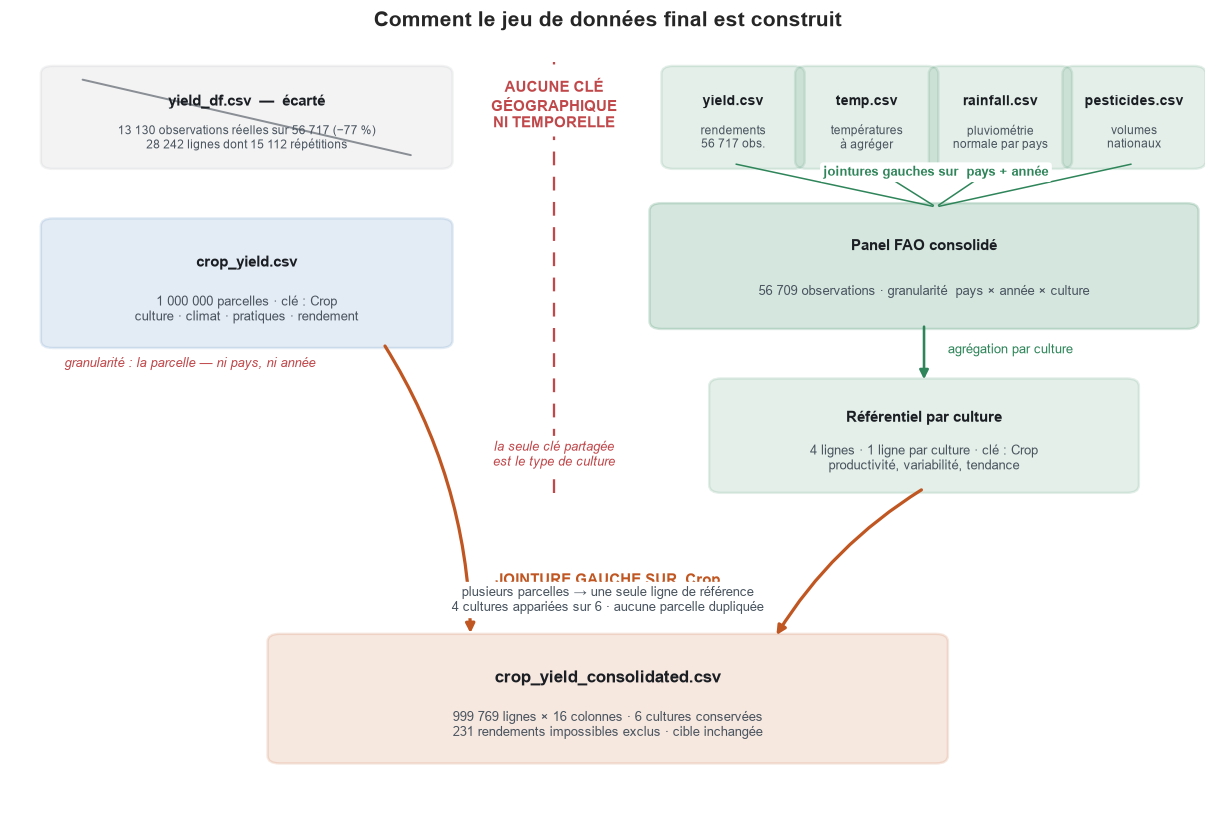

In [31]:
def boite(ax, x, y, largeur, hauteur, titre, detail, couleur,
          alpha=0.13, taille_titre=10, taille_detail=8.3):
    ax.add_patch(FancyBboxPatch((x, y), largeur, hauteur, boxstyle="round,pad=0.010",
                                linewidth=1.6, edgecolor=couleur,
                                facecolor=couleur, alpha=alpha, zorder=2))
    ax.text(x + largeur / 2, y + hauteur * 0.68, titre, ha="center", va="center",
            fontsize=taille_titre, fontweight="bold", color="#1b1f24", zorder=3)
    ax.text(x + largeur / 2, y + hauteur * 0.27, detail, ha="center", va="center",
            fontsize=taille_detail, color="#4a5560", zorder=3)


def fleche(ax, depart, arrivee, couleur, style="-|>", largeur=1.7, courbure=0.0, tirets=None):
    ax.annotate("", xy=arrivee, xytext=depart,
                arrowprops=dict(arrowstyle=style, color=couleur, linewidth=largeur,
                                linestyle=tirets or "solid",
                                connectionstyle=f"arc3,rad={courbure}"))


fig, ax = plt.subplots(figsize=(14, 9))
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis("off")

# ----- Les quatre sources historiques -----
sources = [("yield.csv", "rendements\n56 717 obs."),
           ("temp.csv", "températures\nà agréger"),
           ("rainfall.csv", "pluviométrie\nnormale par pays"),
           ("pesticides.csv", "volumes\nnationaux")]
for k, (nom, detail) in enumerate(sources):
    boite(ax, 0.555 + k * 0.112, 0.855, 0.100, 0.115, nom, detail, GREEN,
          taille_titre=9, taille_detail=7.6)
    fleche(ax, (0.605 + k * 0.112, 0.852), (0.775, 0.795), GREEN, "-", 1.0)

ax.text(0.775, 0.836, "jointures gauches sur  pays + année", ha="center",
        fontsize=8.8, fontweight="bold", color=GREEN, zorder=4, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none"))

boite(ax, 0.545, 0.645, 0.44, 0.145, "Panel FAO consolidé",
      "56 709 observations · granularité  pays × année × culture", GREEN, alpha=0.20)

fleche(ax, (0.765, 0.642), (0.765, 0.565), GREEN)
ax.text(0.785, 0.603, "agrégation par culture", fontsize=8.8, color=GREEN, ha="left")

boite(ax, 0.595, 0.430, 0.34, 0.130, "Référentiel par culture",
      "4 lignes · 1 ligne par culture · clé : Crop\nproductivité, variabilité, tendance", GREEN)

# ----- Le jeu de parcelles -----
boite(ax, 0.035, 0.620, 0.325, 0.150, "crop_yield.csv",
      "1 000 000 parcelles · clé : Crop\nculture · climat · pratiques · rendement", BLUE)
ax.text(0.150, 0.585, "granularité : la parcelle — ni pays, ni année", ha="center",
        fontsize=8.5, style="italic", color="#c0484b")

# ----- Le fichier ecarte -----
boite(ax, 0.035, 0.855, 0.325, 0.115, "yield_df.csv  —  écarté",
      "13 130 observations réelles sur 56 717 (−77 %)\n28 242 lignes dont 15 112 répétitions",
      "#8a8f96", alpha=0.10, taille_titre=9.5, taille_detail=7.6)
ax.plot([0.06, 0.335], [0.962, 0.863], color="#8a8f96", linewidth=1.3)

# ----- La frontiere : elle ne descend pas jusqu'a la convergence -----
ax.plot([0.455, 0.455], [0.42, 0.985], color="#c0484b", linestyle=(0, (6, 5)), linewidth=1.5)
ax.text(0.455, 0.930, "AUCUNE CLÉ\nGÉOGRAPHIQUE\nNI TEMPORELLE", ha="center", va="center",
        fontsize=9.5, fontweight="bold", color="#c0484b",
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="none"))
ax.text(0.455, 0.470, "la seule clé partagée\nest le type de culture", ha="center", va="center",
        fontsize=8.5, color="#c0484b", style="italic",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="none"))

# ----- La convergence vers le livrable -----
boite(ax, 0.225, 0.075, 0.55, 0.150, "crop_yield_consolidated.csv",
      "999 769 lignes × 16 colonnes · 6 cultures conservées\n231 rendements impossibles exclus · cible inchangée",
      ORANGE, alpha=0.14, taille_titre=11, taille_detail=8.6)

fleche(ax, (0.312, 0.616), (0.385, 0.232), ORANGE, largeur=2.1, courbure=-0.14)
fleche(ax, (0.765, 0.426), (0.640, 0.230), ORANGE, largeur=2.1, courbure=0.12)

ax.text(0.500, 0.300, "JOINTURE GAUCHE SUR  Crop", ha="center",
        fontsize=10, fontweight="bold", color=ORANGE, zorder=4, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none"))
ax.text(0.500, 0.265, "plusieurs parcelles → une seule ligne de référence\n"
                      "4 cultures appariées sur 6 · aucune parcelle dupliquée",
        ha="center", fontsize=8.5, color="#4a5560", zorder=4, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none"))

ax.set_title("Comment le jeu de données final est construit", fontsize=14,
             fontweight="bold", pad=16)
enregistrer(fig, "strategie_assemblage.png")
plt.show()

### 10.2 Les leviers du rendement

écrit : reports\figures\leviers_rendement.png — 72 Ko


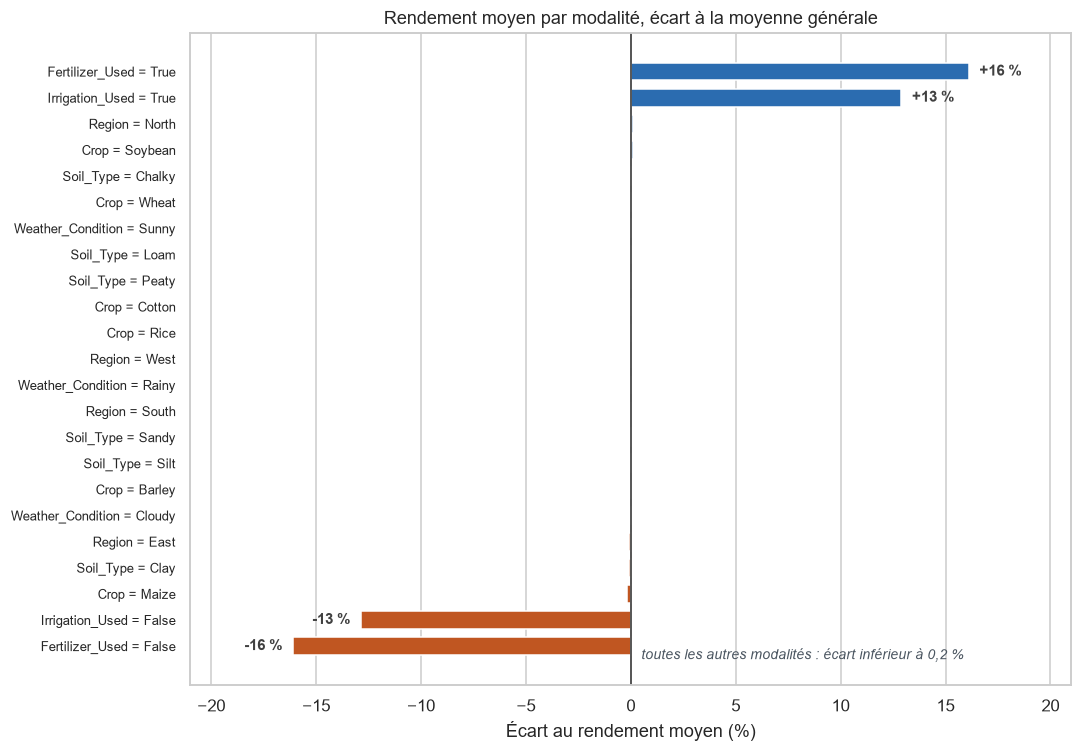

In [32]:
moyenne = dataset[TARGET].mean()
leviers = []
for variable in ['Fertilizer_Used', 'Irrigation_Used'] + CAT_BRUTES:
    moyennes = dataset.groupby(variable, observed=True)[TARGET].mean()
    for modalite, valeur in moyennes.items():
        leviers.append({'libelle': f'{variable} = {modalite}',
                        'ecart_pct': 100 * (valeur / moyenne - 1)})

leviers = pd.DataFrame(leviers).sort_values('ecart_pct')

fig, ax = plt.subplots(figsize=(10, 7))
couleurs = [BLUE if v >= 0 else ORANGE for v in leviers['ecart_pct']]
ax.barh(range(len(leviers)), leviers['ecart_pct'], color=couleurs, height=0.68)
ax.set_yticks(range(len(leviers)))
ax.set_yticklabels(leviers['libelle'], fontsize=8.5)
ax.axvline(0, color='0.3', linewidth=1.2)
ax.set(xlabel='Écart au rendement moyen (%)', xlim=(-21, 21),
       title='Rendement moyen par modalité, écart à la moyenne générale')
ax.grid(axis='y', visible=False)

for position, valeur in enumerate(leviers['ecart_pct']):
    if abs(valeur) > 1:
        ax.annotate(format(valeur, '+.0f') + ' %', (valeur, position),
                    xytext=(7 if valeur > 0 else -7, 0), textcoords='offset points',
                    va='center', ha='left' if valeur > 0 else 'right',
                    fontsize=9.5, fontweight='bold', color='0.25')

ax.text(0.5, -0.5, 'toutes les autres modalités : écart inférieur à 0,2 %',
        fontsize=9, style='italic', color='#4a5560')
fig.tight_layout()
enregistrer(fig, 'leviers_rendement.png')
plt.show()

### 10.3 Ce que coûtait le fichier pré-assemblé

écrit : reports\figures\perte_donnees.png — 52 Ko


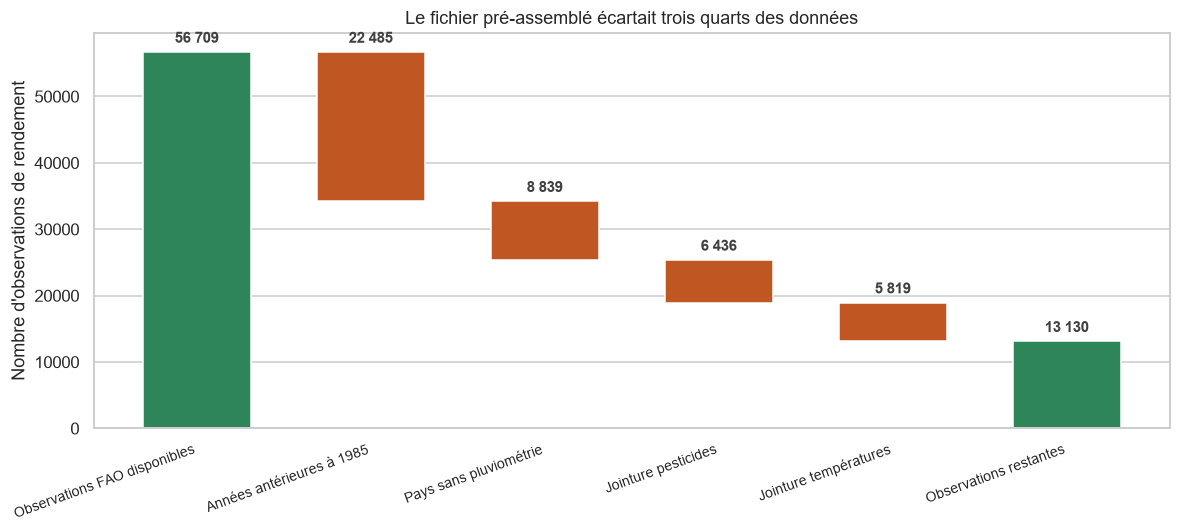

In [33]:
# Recalcul de la cascade de pertes, depuis les fichiers sources
depart = len(rendements)
debut_pluie = pluie['Year'].min()
hors_plage = int((rendements['Year'] < debut_pluie).sum())
apres_pluie = rendements.merge(pluie, on=['Area', 'Year'])
apres_pest = apres_pluie.merge(pesticides, on=['Area', 'Year'])
cles_finales = (apres_pest.merge(temperatures, on=['Area', 'Year'])
                .drop_duplicates(subset=KEY_FAO).shape[0])

etapes = [
    ('Observations FAO disponibles', depart),
    (f'Années antérieures à {debut_pluie}', -hors_plage),
    ('Pays sans pluviométrie', -(depart - hors_plage - len(apres_pluie))),
    ('Jointure pesticides', -(len(apres_pluie) - len(apres_pest))),
    ('Jointure températures', -(len(apres_pest) - cles_finales)),
    ('Observations restantes', cles_finales),
]

fig, ax = plt.subplots(figsize=(11, 5))
base, positions, hauteurs, couleurs = 0, [], [], []
for k, (libelle, valeur) in enumerate(etapes):
    if k in (0, len(etapes) - 1):
        positions.append(0); hauteurs.append(valeur); couleurs.append(GREEN)
        base = valeur if k == 0 else base
    else:
        base += valeur
        positions.append(base); hauteurs.append(-valeur); couleurs.append(ORANGE)

ax.bar(range(len(etapes)), hauteurs, bottom=positions, color=couleurs, width=0.62)
ax.set_xticks(range(len(etapes)))
ax.set_xticklabels([e[0] for e in etapes], rotation=20, ha='right', fontsize=9)
ax.set(ylabel="Nombre d'observations de rendement",
       title='Le fichier pré-assemblé écartait trois quarts des données')
ax.grid(axis='x', visible=False)

for k, (libelle, valeur) in enumerate(etapes):
    sommet = positions[k] + hauteurs[k]
    ax.annotate(format(abs(valeur), ',d').replace(',', ' '),
                (k, sommet), xytext=(0, 6), textcoords='offset points',
                ha='center', fontsize=9.5, fontweight='bold', color='0.25')

fig.tight_layout()
enregistrer(fig, 'perte_donnees.png')
plt.show()

### 10.4 Des rendements très proches entre cultures

écrit : reports\figures\cultures_indiscernables.png — 34 Ko


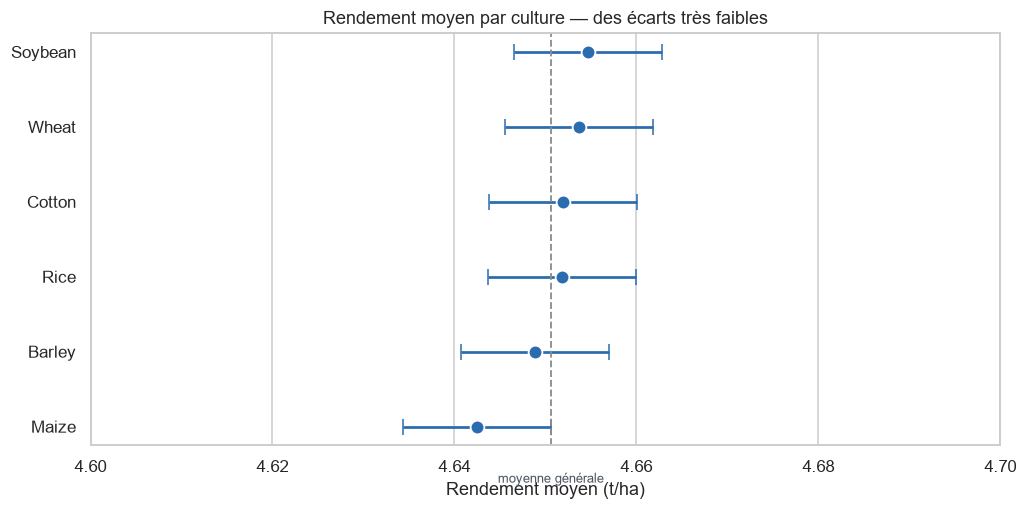

In [34]:
stats_cultures = dataset.groupby('Crop', observed=True)[TARGET].agg(['mean', 'std', 'count'])
stats_cultures['ic95'] = 1.96 * stats_cultures['std'] / np.sqrt(stats_cultures['count'])
stats_cultures = stats_cultures.sort_values('mean')

fig, ax = plt.subplots(figsize=(9.5, 4.8))
positions = np.arange(len(stats_cultures))
ax.errorbar(stats_cultures['mean'], positions, xerr=stats_cultures['ic95'],
            fmt='none', ecolor=BLUE, elinewidth=1.8, capsize=5, zorder=2)
ax.plot(stats_cultures['mean'], positions, 'o', color=BLUE, markersize=9,
        markeredgecolor='white', markeredgewidth=1.2, linestyle='none', zorder=3)

ax.axvline(dataset[TARGET].mean(), color='0.55', linestyle='--', linewidth=1.2)
ax.set_yticks(positions)
ax.set_yticklabels(stats_cultures.index)
ax.set(xlabel='Rendement moyen (t/ha)', xlim=(4.60, 4.70),
       title='Rendement moyen par culture — des écarts très faibles')
ax.grid(axis='y', visible=False)
ax.text(dataset[TARGET].mean(), -0.75, 'moyenne générale', ha='center',
        fontsize=8.5, color='#4a5560')

fig.tight_layout()
enregistrer(fig, 'cultures_indiscernables.png')
plt.show()

### 10.5 Ce que montre l'analyse en composantes principales

écrit : reports\figures\acp_variables.png — 88 Ko


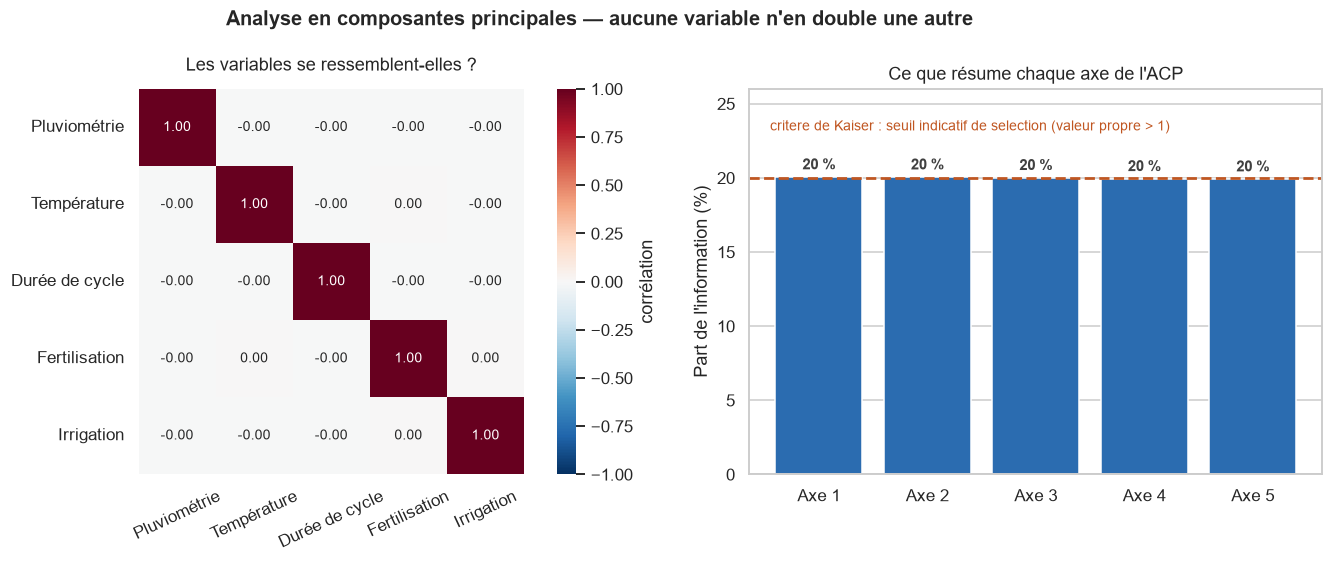

In [35]:
# Deux facons de montrer la meme chose : la matrice de correlation (intuitive)
# et l'eboulis de l'ACP (la mesure formelle)
VARIABLES_ACP = ['Rainfall_mm', 'Temperature_Celsius', 'Days_to_Harvest',
                 'Fertilizer_Used', 'Irrigation_Used']
ETIQUETTES = ['Pluviométrie', 'Température', 'Durée de cycle', 'Fertilisation', 'Irrigation']

donnees_acp = dataset[VARIABLES_ACP].astype(float)
matrice = donnees_acp.corr()
acp_rapport = PCA().fit(StandardScaler().fit_transform(donnees_acp))
inerties = 100 * acp_rapport.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2),
                         gridspec_kw={'width_ratios': [1.15, 1]})

sns.heatmap(matrice, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={'label': 'corrélation'}, ax=axes[0],
            xticklabels=ETIQUETTES, yticklabels=ETIQUETTES, annot_kws={'fontsize': 9})
axes[0].set_title('Les variables se ressemblent-elles ?', fontsize=11.5, pad=12)
axes[0].tick_params(axis='x', rotation=25)
axes[0].tick_params(axis='y', rotation=0)

axes[1].bar([f'Axe {i}' for i in range(1, len(inerties) + 1)], inerties, color=BLUE)
axes[1].axhline(100 / len(inerties), color=ORANGE, linestyle='--', linewidth=1.8)
axes[1].text(-0.45, 23.2, 'critere de Kaiser : seuil indicatif de selection (valeur propre > 1)',
             fontsize=9, color=ORANGE, ha='left')
axes[1].set(ylabel="Part de l'information (%)", ylim=(0, 26),
            title="Ce que résume chaque axe de l'ACP")
axes[1].grid(axis='x', visible=False)
for k, valeur in enumerate(inerties):
    axes[1].annotate(f'{valeur:.0f} %', (k, valeur), xytext=(0, 5),
                     textcoords='offset points', ha='center',
                     fontsize=9.5, fontweight='bold', color='0.25')

fig.suptitle("Analyse en composantes principales — aucune variable n'en double une autre",
             fontsize=13, fontweight='bold')
fig.tight_layout()
enregistrer(fig, 'acp_variables.png')
plt.show()

> Ces quatre figures sont référencées dans `reports/data_preparation_summary.md`. Les régénérer suffit à mettre le rapport à jour.

## 11. Synthèse

### Les six variables créées

| # | Variable | Niveau | Statut |
|---|---|---|---|
| 1 | `crop_productivity_index` | Culture | Indice relatif **partiellement** normalisé — effet pays réduit, pas annulé |
| 2 | `crop_yield_geo_cv` | Culture | **Variabilité géographique**, pas un risque parcellaire |
| 3 | `crop_yield_trend_decade` | Culture | Tendance descriptive, sensible au périmètre |
| 4 | `crop_in_fao_reference` | Culture | Rend lisibles les valeurs manquantes |
| 5 | `inputs_level` | Parcelle | Résume les deux pratiques sans les remplacer |
| 6 | `low_rain_no_irrigation` | Parcelle | Indicateur descriptif, seuil conventionnel |

**Quatre variables ont été construites puis écartées du livrable.** Deux comparaient une température de parcelle à une moyenne annuelle nationale — grandeurs non commensurables (§7.3). Deux autres étaient redondantes avec celles retenues ; elles restent dans `crop_reference.csv`.

### Ce que la validation établit

Hors échantillon, catégorielles comprises, les quatre jeux de variables donnent le **même R² ≈ 0,913 et le même RMSE ≈ 0,50**. La référence non paramétrique de §8.2 va dans le même sens : stratifier en plus par culture **dégrade** la performance.

Aucun des modèles et tests employés ne met en évidence d'effet exploitable de la culture. Ce n'est pas une démonstration qu'aucun modèle n'y parviendrait jamais, mais le faisceau est serré, et les tests conditionnels de §8.3 le confirment.

### À trancher à l'étape de modélisation

**La différenciation entre cultures.** L'application doit classer les cultures ; les données d'entraînement n'en portent pas l'information. Deux voies, et le choix est **métier** :

1. **Injecter une calibration externe** depuis le référentiel FAO, en documentant qu'il s'agit d'une hypothèse de transfert — à évaluer, non à supposer.
2. **Renoncer au classement différencié** et présenter l'application comme un prédicteur de rendement.

**Aucune calibration n'est appliquée ici** : la cible exportée est identique à l'originale, contrôlé en §9. Même principe pour l'imputation des cultures sans référence, laissée au pipeline et ajustée sur l'entraînement seul.

### Limite à porter au rapport métier

L'indice compare des **tonnages**, pas des valeurs économiques. La rentabilité dépend des prix et des coûts, dont aucune donnée n'est fournie. Le classement affiché devra être présenté comme un classement de **rendement physique**.